In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

from keras.callbacks import EarlyStopping
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten
from keras.utils import to_categorical
from keras.utils import set_random_seed
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from keras.utils import image_dataset_from_directory

<div style="font-size: 0.85em; line-height: 1.4;">

**Question 1**

**A. Understand the Problem:** Define your classification task clearly. What classes are you distinguishing, and what is the practical use case?

Non-verbal pain assessment, ill be using all the categories to distinguish with the model during testing.

</div>


In [ ]:
!unzip face.zip

Archive:  face.zip
replace test/angry/PrivateTest_10131363.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
#datasets
train = "/content/train"
test = "/content/test"

batch_size = 33
epochs = 30
seed = 12

In [ ]:
set_random_seed(seed)

In [ ]:
print(training_data.class_names)

['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [ ]:
from keras.utils import image_dataset_from_directory

training_data = image_dataset_from_directory(
    train,
    batch_size=batch_size,
    image_size=(64, 64),
    seed=seed,
    validation_split=0.2,
    subset="training"
)

validation_data = image_dataset_from_directory(
    train,
    batch_size=batch_size,
    image_size=(64, 64),
    seed=seed,
    validation_split=0.2,
    subset="validation"
)

testing_data = image_dataset_from_directory(
    test,
    batch_size=batch_size,
    image_size=(64, 64),
    shuffle=False
)

Found 28709 files belonging to 7 classes.
Using 22968 files for training.
Found 28709 files belonging to 7 classes.
Using 5741 files for validation.
Found 7178 files belonging to 7 classes.


In [ ]:
for data_batch, label_batch in training_data.take(1):
    print('data batch shape ', data_batch.shape)
    print('label batch shape ', label_batch.shape)

data batch shape  (33, 64, 64, 3)
label batch shape  (33,)


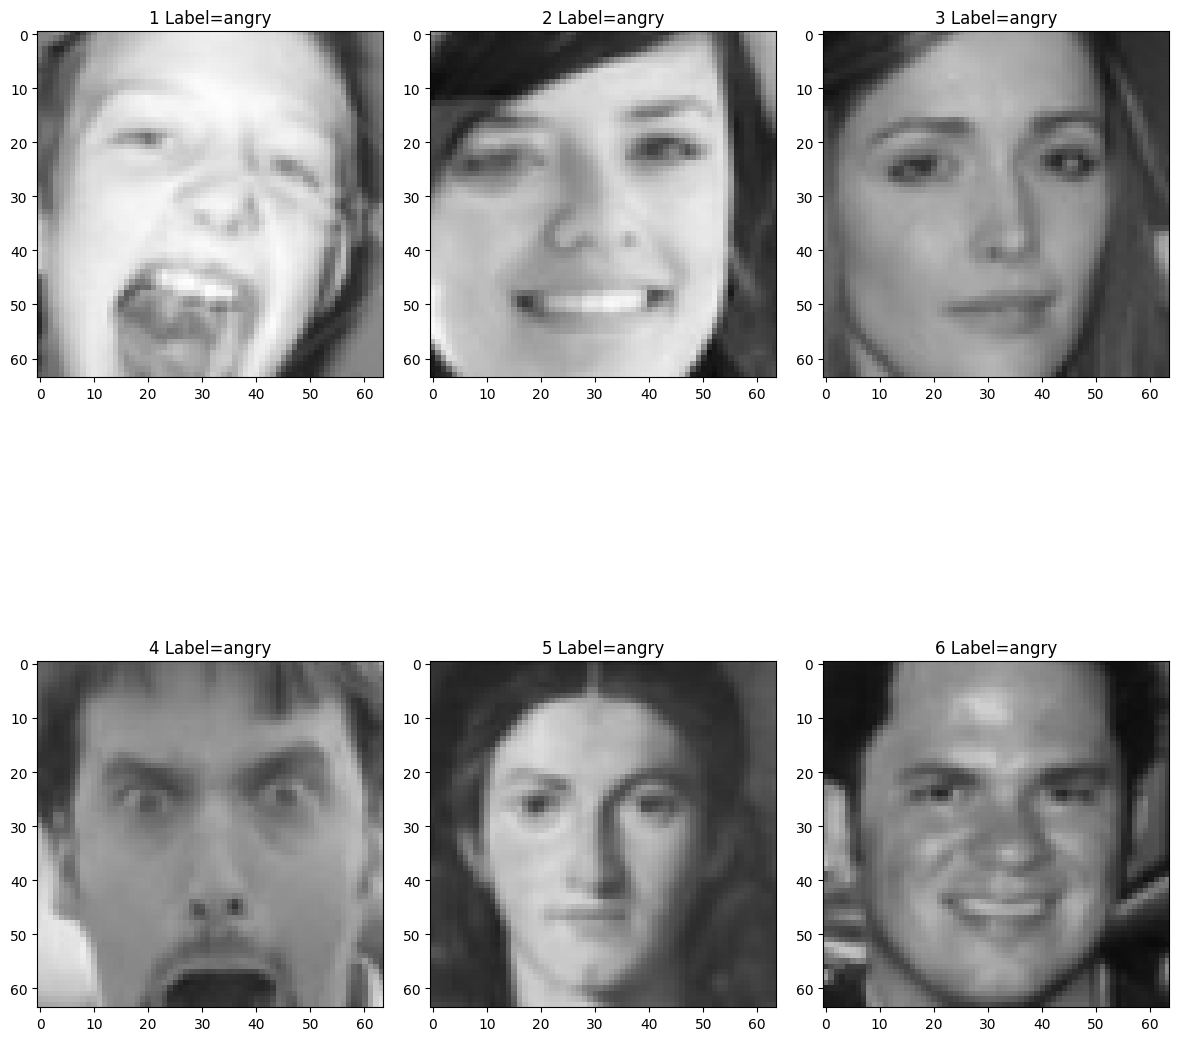

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

class_names = training_data.class_names

fig = plt.figure(figsize=(12, 15))
columns = 3
rows = 2

for i in range(1, 7):
    img = data_batch[i] / 255
    ax = fig.add_subplot(rows, columns, i)

    lbl_index = np.argmax(label_batch[i])
    lbl_name = class_names[lbl_index]

    fig.tight_layout()
    ax.title.set_text(str(i) + " Label=" + lbl_name)
    plt.imshow(img)

plt.show()

In [ ]:
from sklearn.utils import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(np.concatenate([y.numpy() for x, y in training_data])),
    y=np.concatenate([y.numpy() for x, y in training_data])
)

class_weight_dict = dict(zip(
    np.unique(np.concatenate([y.numpy() for x, y in training_data])),
    class_weights
))

class_weight_dict

{np.int32(0): np.float64(1.037679587964218),
 np.int32(1): np.float64(9.295022258195063),
 np.int32(2): np.float64(1.0086513547933775),
 np.int32(3): np.float64(0.56347979686465),
 np.int32(4): np.float64(0.8344717337596279),
 np.int32(5): np.float64(0.8417503481638936),
 np.int32(6): np.float64(1.2882382635032812)}

In [ ]:
# Import
from keras import models, layers
from keras.utils import set_random_seed

set_random_seed(seed)

# Step 2
network = models.Sequential()

network.add(layers.Input(shape=(64, 64, 3)))

network.add(layers.RandomFlip("horizontal"))  #Augmentation
network.add(layers.RandomRotation(0.05))
network.add(layers.RandomZoom(0.05))

network.add(layers.Flatten())

network.add(layers.Dense(256, activation='relu'))
network.add(layers.Dropout(0.3))

network.add(layers.Dense(128, activation='relu'))
network.add(layers.Dropout(0.3))

network.add(layers.Dense(7, activation='softmax'))

network.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_6 (RandomFlip)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_6               │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_6 (RandomZoom)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 256)            │     3,145,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,179,783 (12.13 MB)

 Trainable params: 3,179,783 (12.13 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# STep3: Compile
from keras import callbacks
from keras.optimizers import Adam

network.compile(loss='sparse_categorical_crossentropy',optimizer='adam',metrics=['accuracy'])

callbacks_phase = [
    callbacks.ModelCheckpoint(
        filepath="best_model.keras",
        save_best_only=True,
        monitor="val_loss",
        verbose=1
    ),

    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    ),
]
#STep4: Fitting
history = network.fit(training_data, validation_data=validation_data, epochs=epochs, callbacks=callbacks_phase, class_weight=class_weight_dict)

Epoch 1/30
690/696 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1015 - loss: 2.3925
Epoch 1: val_loss improved from None to 1.94243, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
696/696 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.0932 - loss: 2.0425 - val_accuracy: 0.1449 - val_loss: 1.9424
Epoch 2/30
692/696 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1238 - loss: 1.9607
Epoch 2: val_loss did not improve from 1.94243
696/696 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.1022 - loss: 1.9476 - val_accuracy: 0.2425 - val_loss: 1.9429
Epoch 3/30
689/696 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1418 - loss: 1.9572
Epoch 3: val_loss did not improve from 1.94243
696/696 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.1105 - loss: 1.9462 - val_accuracy: 0.1625 - val_loss: 1.9428
Epoch 4/30
692/696 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1237 - loss: 1.9572
Epoch 4: val_loss did not improve from 1.94243
696/696 ━━━━━━━━━━━━━━

In [ ]:
history_df = pd.DataFrame(history.history)
history_df.head()

,accuracy,loss,val_accuracy,val_loss
0,0.093173,2.042463,0.144922,1.942430
1,0.102229,1.947622,0.242466,1.942895
2,0.110502,1.946228,0.162515,1.942779
3,0.099791,1.948577,0.162515,1.943659
4,0.125087,1.946400,0.242641,1.941630


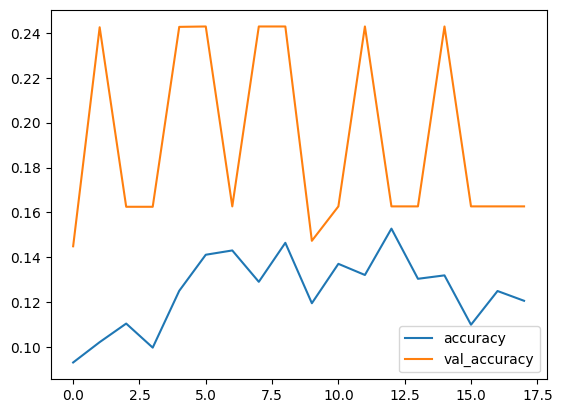

In [ ]:
history_df[['accuracy', 'val_accuracy']].plot();

218/218 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


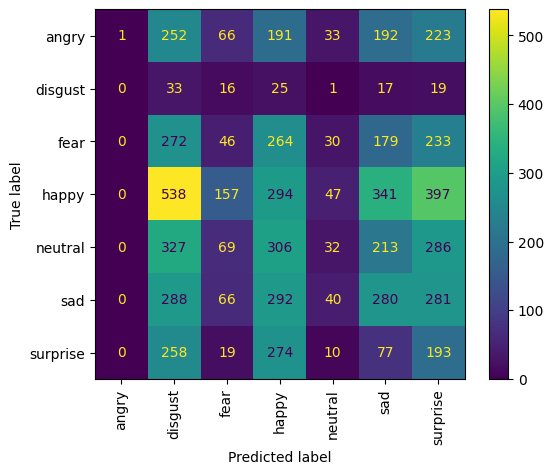

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Actual labels
y_test = np.concatenate([labels.numpy() for images, labels in testing_data])

# Predicted labels
y_pred_test = np.argmax(network.predict(testing_data), axis=1)

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test,
    display_labels=class_names,
    xticks_rotation='vertical'
);

In [ ]:
network.save('pain_assessment_model.keras')

In [ ]:
from google.colab import files
files.download('pain_assessment_model.keras')

Training data:
{'angry': np.int64(3162), 'disgust': np.int64(353), 'fear': np.int64(3253), 'happy': np.int64(5823), 'neutral': np.int64(3932), 'sad': np.int64(3898), 'surprise': np.int64(2547)}
Validation data:
{'angry': np.int64(833), 'disgust': np.int64(83), 'fear': np.int64(844), 'happy': np.int64(1392), 'neutral': np.int64(1033), 'sad': np.int64(932), 'surprise': np.int64(624)}
Testing data:
{'angry': np.int64(958), 'disgust': np.int64(111), 'fear': np.int64(1024), 'happy': np.int64(1774), 'neutral': np.int64(1233), 'sad': np.int64(1247), 'surprise': np.int64(831)}
